In [47]:
import pandas as pd
import numpy as np
import os
os.chdir("/mnt/zarrinpar/scratch/sfloresr/AD_EM/")

In [48]:
from qiime2 import Artifact

In [49]:
from skbio.stats import subsample_counts
from skbio.diversity import alpha_diversity

In [50]:
from collections import defaultdict
from itertools import chain, combinations, repeat, zip_longest

In [51]:
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib_venn import venn3, venn2

In [52]:
%matplotlib inline
sns.set(style='ticks')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'  # render SVG text as text, not curves
plt.rcParams['lines.markersize'] = 15

## taxonomy computations

In [53]:
def taxon2cols(taxon, drop_uncultured=False):
    rank_prefix = (
        "Kingdom",
        "Phylum",
        "Class",
        "Order",
        "Family",
        "Genus",
        "Species",
    )
    ranks = taxon.split("; ")
    if drop_uncultured:
        for n,v in enumerate(ranks):
            if 'metagenome' in v or 'uncultured' in v or v[-1] == '_':
                del ranks[n:]
                break
    return pd.Series(dict(zip_longest(rank_prefix, ranks, fillvalue=ranks[-1])))

In [54]:
tax_file = '/mnt/zarrinpar/Pynchon/Databases/wol2/taxonomy/lineages.txt'
tax = pd.read_csv(tax_file, sep='\t', names=['genome', 'lineage'], index_col=0)
tax.head()

,lineage
genome,
G000005825,d__Bacteria; p__Firmicutes; c__Bacilli; o__Bac...
G000006175,d__Archaea; p__Methanobacteriota_A; c__Methano...
G000006605,d__Bacteria; p__Actinobacteriota; c__Actinomyc...
G000006725,d__Bacteria; p__Proteobacteria; c__Gammaproteo...
G000006745,d__Bacteria; p__Proteobacteria; c__Gammaproteo...


In [55]:
# get species/family names
tax_tbl = tax.lineage.apply(lambda x: taxon2cols(x, drop_uncultured=True))
tax_tbl['species_name'] = tax_tbl.index.to_frame()['genome'].str[-4:] + ":" + tax_tbl.Species
tax_tbl['family_name'] = tax_tbl.index.to_frame()['genome'].str[-4:] + ":" + tax_tbl.Family
tax_tbl.head()


,Kingdom,Phylum,Class,Order,Family,Genus,Species,species_name,family_name
genome,,,,,,,,,
G000005825,d__Bacteria,p__Firmicutes,c__Bacilli,o__Bacillales_H,f__Bacillaceae_D,g__Bacillus_S,s__Bacillus_S pseudofirmus,5825:s__Bacillus_S pseudofirmus,5825:f__Bacillaceae_D
G000006175,d__Archaea,p__Methanobacteriota_A,c__Methanococci,o__Methanococcales,f__Methanococcaceae,g__Methanococcus,s__Methanococcus voltae_A,6175:s__Methanococcus voltae_A,6175:f__Methanococcaceae
G000006605,d__Bacteria,p__Actinobacteriota,c__Actinomycetia,o__Mycobacteriales,f__Mycobacteriaceae,g__Corynebacterium,s__Corynebacterium jeikeium,6605:s__Corynebacterium jeikeium,6605:f__Mycobacteriaceae
G000006725,d__Bacteria,p__Proteobacteria,c__Gammaproteobacteria,o__Xanthomonadales,f__Xanthomonadaceae,g__Xylella,s__Xylella fastidiosa,6725:s__Xylella fastidiosa,6725:f__Xanthomonadaceae
G000006745,d__Bacteria,p__Proteobacteria,c__Gammaproteobacteria,o__Enterobacterales,f__Vibrionaceae,g__Vibrio,s__Vibrio cholerae,6745:s__Vibrio cholerae,6745:f__Vibrionaceae


# load metadata

In [56]:
md = pd.read_csv('metagenomics/data_files/stool.metagenomic.metadata.with_amyloid.tsv', sep='\t', index_col=0)
md.index = md.index.str.replace(r'^\d+\.', '', regex=True)
sorted(list(md.columns))

['TRF_start_age_mo',
 'TRF_start_date',
 'age_of_collection_days',
 'age_of_collection_months',
 'box',
 'brain_insoluble_ab40',
 'brain_insoluble_ab42',
 'brain_lysate_ab40',
 'brain_lysate_ab42',
 'brain_soluble_ab40',
 'brain_soluble_ab42',
 'cage_id',
 'collection_timepoint',
 'collection_timestamp',
 'dab_area_cortex',
 'dab_area_hippocampus',
 'dab_count_cortex',
 'dab_count_hippocampus',
 'date_of_collection',
 'description',
 'dna_extracted',
 'dob',
 'elevation',
 'empo_1',
 'empo_2',
 'empo_3',
 'env_biome',
 'env_feature',
 'env_material',
 'env_package',
 'feeding_condition',
 'genotype_diet',
 'geo_loc_name',
 'host_age',
 'host_age_units',
 'host_body_habitat',
 'host_body_product',
 'host_body_site',
 'host_common_name',
 'host_scientific_name',
 'host_subject_id',
 'host_taxid',
 'host_weight',
 'host_weight_units',
 'iacuc_institute',
 'iacuc_protocol_id',
 'katharoseq_cell_count',
 'katharoseq_community_type',
 'katharoseq_control_type',
 'katharoseq_plate_number',
 '

In [57]:
md.drop([r for r in md.index if 'BLANK' in r], inplace=True)

In [58]:
md['genotype_diet'] = md.mouse_genotype + "." + md.feeding_condition
md.genotype_diet.value_counts()

Tg.ALF     53
Tg.TRF     50
Ntg.ALF    42
Name: genotype_diet, dtype: int64

In [59]:
genotype_diet_order = ['Ntg.ALF', 'Tg.ALF', 'Tg.TRF']
genotype_diet_groups = [
    ['Ntg.ALF', 'Tg.ALF', 'Tg.TRF'],
    ['Ntg.ALF', 'Tg.ALF'],
    ['Tg.ALF', 'Tg.TRF'],
]
genotype_diet_palette = {
    'Tg.ALF': 'purple',
    'Ntg.ALF': 'orange',
    'Tg.TRF': 'green',
}

In [60]:
sex_order = ('male', 'female')
sex_markers = {'male': 'o', 'female': 'D'}

In [61]:
md['zt_time'] = md.zt_collection_time.str.replace('ZT','', regex=False).astype(int)
md['zt_collection_time'] = 'ZT' + md.zt_time.astype(str).str.zfill(2)
md.zt_collection_time.unique()

array(['ZT08', 'ZT20', 'ZT12', 'ZT16', 'ZT00', 'ZT04'], dtype=object)

In [62]:
md.head()

,title,empo_1,empo_2,empo_3,latitude,taxon_id,elevation,env_biome,longitude,description,...,serum_ab40_ab42_ratio,serum_ab42_ab40_ratio,brain_lysate_ab40,brain_lysate_ab42,brain_insoluble_ab40,brain_insoluble_ab42,brain_soluble_ab40,brain_soluble_ab42,genotype_diet,zt_time
sample_name,,,,,,,,,,,,,,,,,,,,,
332.T8.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,18.073368,0.055330,406.741573,27.528090,80300.239234,20058.612440,406.741573,27.528090,Tg.ALF,8
314.T20.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,3.468113,0.288341,460.338983,32.881356,46088.495575,16899.705015,460.338983,32.881356,Tg.ALF,20
320.T8.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ntg.ALF,8
319.T12.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Tg.ALF,12
322.T16.S,ALZ/TRF,Host-associated,Animal,Animal proximal gut,32.5,410661,193,urban biome,-117.25,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ntg.ALF,16


# Presence/Absence

In [63]:
threshold = 1
genotype_diets = ('Ntg.ALF', 'Tg.ALF', 'Tg.TRF')
ranks = ('free','family','genus','order','species')
presence_by_rank = defaultdict(lambda :defaultdict(set))
for rank in ranks:
    sub_df = pd.read_csv(f'metagenomics/data_files/{rank.lower()}.micov_005.csv', index_col=0)
    # display(sub_df.head())
    sub_df = sub_df.drop([c for c in sub_df.columns if 'BLANK' in c], axis='columns')
    # display(sub_df.head())
    by_md = sub_df.T.join(md.genotype_diet).groupby('genotype_diet').agg('sum')
    display(by_md)
    for cond in genotype_diets:
        counts = by_md.loc[cond]
        presence_by_rank[rank][cond] = set(counts[counts>=threshold].index)
        
        

,d__Archaea; p__Thermoplasmatota; c__Thermoplasmata; o__Methanomassiliicoccales; f__Methanomassiliicoccaceae; g__DTU008; s__DTU008 sp001421185,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Bifidobacteriaceae; g__Bifidobacterium; s__Bifidobacterium bifidum,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Bifidobacteriaceae; g__Bifidobacterium; s__Bifidobacterium longum,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Dermatophilaceae; g__Serinicoccus; s__Serinicoccus profundi,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Microbacteriaceae; g__Clavibacter; s__Clavibacter sepedonicus,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Microbacteriaceae; g__Curtobacterium; s__Curtobacterium flaccumfaciens_A,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Microbacteriaceae; g__Curtobacterium; s__Curtobacterium oceanosedimentum,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Microbacteriaceae; g__Frigoribacterium; s__Frigoribacterium sp001424645,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Micrococcaceae; g__Kocuria; s__Kocuria rosea,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Micrococcaceae; g__Micrococcus; s__Micrococcus luteus,...,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas; s__Xanthomonas fragariae,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas; s__Xanthomonas hortorum_A,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas; s__Xanthomonas oryzae,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas_A; s__Xanthomonas_A sontii,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas_A; s__Xanthomonas_A translucens,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas_B; s__Xanthomonas_B massiliensis,d__Bacteria; p__Spirochaetota; c__Spirochaetia; o__Treponematales; f__Treponemataceae; g__Treponema_D; s__Treponema_D succinifaciens,d__Bacteria; p__Spirochaetota; c__Spirochaetia; o__Treponematales; f__Treponemataceae; g__Treponema_F; s__,d__Bacteria; p__Verrucomicrobiota; c__Verrucomicrobiae; o__Opitutales; f__DSM-45221; g__BACL24; s__BACL24 sp002430605,d__Bacteria; p__Verrucomicrobiota; c__Verrucomicrobiae; o__Verrucomicrobiales; f__Akkermansiaceae; g__Akkermansia; s__Akkermansia muciniphila
genotype_diet,,,,,,,,,,,,,,,,,,,,,
Ntg.ALF,1912.0,2018.0,4.0,0.0,14.0,217.0,14.0,27.0,2.0,5.0,...,14.0,26.0,17.0,77.0,3807.0,5.0,2071.0,0.0,0.0,350.0
Tg.ALF,3794.0,3252.0,18.0,0.0,615.0,809.0,73.0,227.0,0.0,3.0,...,26.0,8.0,25.0,249.0,6335.0,4.0,3759.0,0.0,1.0,3341.0
Tg.TRF,3733.0,1296.0,13.0,0.0,15.0,291.0,23.0,35.0,0.0,4.0,...,27.0,52.0,38.0,146.0,6294.0,24.0,2992.0,0.0,0.0,471.0


,d__Archaea; p__Thermoplasmatota; c__Thermoplasmata; o__Methanomassiliicoccales; f__Methanomassiliicoccaceae,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Bifidobacteriaceae,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Dermatophilaceae,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Microbacteriaceae,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Micrococcaceae,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Mycobacteriales; f__Mycobacteriaceae,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Mycobacteriales; f__Pseudonocardiaceae,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Propionibacteriales; f__Nocardioidaceae,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Propionibacteriales; f__Propionibacteriaceae,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Streptosporangiales; f__Streptosporangiaceae,...,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Enterobacterales; f__Succinivibrionaceae,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Pseudomonadales; f__Alcanivoracaceae,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Pseudomonadales; f__Halomonadaceae,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Pseudomonadales; f__Moraxellaceae,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Pseudomonadales; f__Pseudomonadaceae,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Steroidobacterales; f__Steroidobacteraceae,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae,d__Bacteria; p__Spirochaetota; c__Spirochaetia; o__Treponematales; f__Treponemataceae,d__Bacteria; p__Verrucomicrobiota; c__Verrucomicrobiae; o__Opitutales; f__DSM-45221,d__Bacteria; p__Verrucomicrobiota; c__Verrucomicrobiae; o__Verrucomicrobiales; f__Akkermansiaceae
genotype_diet,,,,,,,,,,,,,,,,,,,,,
Ntg.ALF,1912.0,2022.0,0.0,272.0,9.0,704.0,0.0,0.0,38.0,0.0,...,756.0,0.0,2.0,9821.0,362.0,0.0,14359.0,2071.0,0.0,350.0
Tg.ALF,3794.0,3270.0,0.0,1724.0,6.0,1639.0,1.0,1.0,233.0,3.0,...,1126.0,0.0,0.0,35223.0,70460.0,6.0,9474.0,3759.0,1.0,3341.0
Tg.TRF,3733.0,1309.0,0.0,364.0,22.0,593.0,0.0,0.0,144.0,5.0,...,3049.0,0.0,7.0,27519.0,10104.0,1.0,31638.0,2992.0,0.0,471.0


,d__Archaea; p__Thermoplasmatota; c__Thermoplasmata; o__Methanomassiliicoccales; f__Methanomassiliicoccaceae; g__DTU008,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Bifidobacteriaceae; g__Bifidobacterium,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Dermatophilaceae; g__Serinicoccus,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Microbacteriaceae; g__Clavibacter,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Microbacteriaceae; g__Curtobacterium,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Microbacteriaceae; g__Frigoribacterium,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Micrococcaceae; g__Kocuria,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Micrococcaceae; g__Micrococcus,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Micrococcaceae; g__Nesterenkonia,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Micrococcaceae; g__Rothia,...,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Stenotrophomonas_A,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Thermomonas,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__VRTS01,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas_A,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas_B,d__Bacteria; p__Spirochaetota; c__Spirochaetia; o__Treponematales; f__Treponemataceae; g__Treponema_D,d__Bacteria; p__Spirochaetota; c__Spirochaetia; o__Treponematales; f__Treponemataceae; g__Treponema_F,d__Bacteria; p__Verrucomicrobiota; c__Verrucomicrobiae; o__Opitutales; f__DSM-45221; g__BACL24,d__Bacteria; p__Verrucomicrobiota; c__Verrucomicrobiae; o__Verrucomicrobiales; f__Akkermansiaceae; g__Akkermansia
genotype_diet,,,,,,,,,,,,,,,,,,,,,
Ntg.ALF,1912.0,2022.0,0.0,14.0,231.0,27.0,2.0,5.0,0.0,2.0,...,20.0,1.0,0.0,63.0,3884.0,5.0,2071.0,0.0,0.0,350.0
Tg.ALF,3794.0,3270.0,0.0,615.0,882.0,227.0,0.0,3.0,2.0,1.0,...,16.0,2.0,0.0,68.0,6584.0,4.0,3759.0,0.0,1.0,3341.0
Tg.TRF,3733.0,1309.0,0.0,15.0,314.0,35.0,0.0,4.0,0.0,18.0,...,78.0,9.0,0.0,140.0,6440.0,24.0,2992.0,0.0,0.0,471.0


,d__Archaea; p__Thermoplasmatota; c__Thermoplasmata; o__Methanomassiliicoccales,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Mycobacteriales,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Propionibacteriales,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Streptosporangiales,d__Bacteria; p__Actinobacteriota; c__Coriobacteriia; o__Coriobacteriales,d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales,d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Chitinophagales,d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Flavobacteriales,d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Sphingobacteriales,...,d__Bacteria; p__Proteobacteria; c__Alphaproteobacteria; o__UBA9219,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Burkholderiales,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Ectothiorhodospirales,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Enterobacterales,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Pseudomonadales,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Steroidobacterales,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales,d__Bacteria; p__Spirochaetota; c__Spirochaetia; o__Treponematales,d__Bacteria; p__Verrucomicrobiota; c__Verrucomicrobiae; o__Opitutales,d__Bacteria; p__Verrucomicrobiota; c__Verrucomicrobiae; o__Verrucomicrobiales
genotype_diet,,,,,,,,,,,,,,,,,,,,,
Ntg.ALF,1912.0,2303.0,704.0,38.0,0.0,515048.0,163830959.0,2621.0,19152.0,98.0,...,13532.0,794274.0,0.0,44609.0,10185.0,0.0,14359.0,2071.0,0.0,350.0
Tg.ALF,3794.0,5000.0,1640.0,234.0,3.0,1477863.0,198320250.0,2582.0,26679.0,371.0,...,18556.0,382794.0,40.0,55298.0,105683.0,6.0,9474.0,3759.0,1.0,3341.0
Tg.TRF,3733.0,1695.0,593.0,144.0,5.0,923789.0,183957546.0,2614.0,15658.0,143.0,...,10687.0,1018292.0,1.0,175237.0,37630.0,1.0,31638.0,2992.0,0.0,471.0


,d__Archaea; p__Thermoplasmatota; c__Thermoplasmata; o__Methanomassiliicoccales; f__Methanomassiliicoccaceae; g__DTU008; s__DTU008 sp001421185,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Bifidobacteriaceae; g__Bifidobacterium; s__Bifidobacterium bifidum,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Bifidobacteriaceae; g__Bifidobacterium; s__Bifidobacterium longum,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Dermatophilaceae; g__Serinicoccus; s__Serinicoccus profundi,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Microbacteriaceae; g__Clavibacter; s__Clavibacter sepedonicus,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Microbacteriaceae; g__Curtobacterium; s__Curtobacterium flaccumfaciens_A,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Microbacteriaceae; g__Curtobacterium; s__Curtobacterium oceanosedimentum,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Microbacteriaceae; g__Frigoribacterium; s__Frigoribacterium sp001424645,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Micrococcaceae; g__Kocuria; s__Kocuria rosea,d__Bacteria; p__Actinobacteriota; c__Actinomycetia; o__Actinomycetales; f__Micrococcaceae; g__Micrococcus; s__Micrococcus luteus,...,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas; s__Xanthomonas fragariae,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas; s__Xanthomonas hortorum_A,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas; s__Xanthomonas oryzae,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas_A; s__Xanthomonas_A sontii,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas_A; s__Xanthomonas_A translucens,d__Bacteria; p__Proteobacteria; c__Gammaproteobacteria; o__Xanthomonadales; f__Xanthomonadaceae; g__Xanthomonas_B; s__Xanthomonas_B massiliensis,d__Bacteria; p__Spirochaetota; c__Spirochaetia; o__Treponematales; f__Treponemataceae; g__Treponema_D; s__Treponema_D succinifaciens,d__Bacteria; p__Spirochaetota; c__Spirochaetia; o__Treponematales; f__Treponemataceae; g__Treponema_F; s__,d__Bacteria; p__Verrucomicrobiota; c__Verrucomicrobiae; o__Opitutales; f__DSM-45221; g__BACL24; s__BACL24 sp002430605,d__Bacteria; p__Verrucomicrobiota; c__Verrucomicrobiae; o__Verrucomicrobiales; f__Akkermansiaceae; g__Akkermansia; s__Akkermansia muciniphila
genotype_diet,,,,,,,,,,,,,,,,,,,,,
Ntg.ALF,1912.0,2018.0,4.0,0.0,14.0,217.0,14.0,27.0,2.0,5.0,...,14.0,26.0,17.0,77.0,3807.0,5.0,2071.0,0.0,0.0,350.0
Tg.ALF,3794.0,3252.0,18.0,0.0,615.0,809.0,73.0,227.0,0.0,3.0,...,26.0,8.0,25.0,249.0,6335.0,4.0,3759.0,0.0,1.0,3341.0
Tg.TRF,3733.0,1296.0,13.0,0.0,15.0,291.0,23.0,35.0,0.0,4.0,...,27.0,52.0,38.0,146.0,6294.0,24.0,2992.0,0.0,0.0,471.0


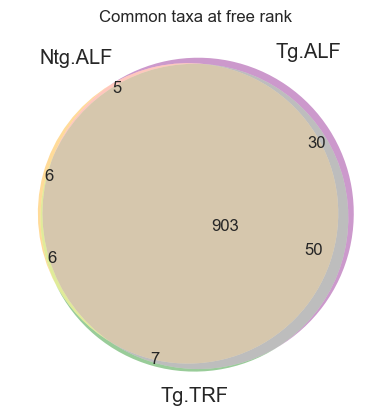

/mnt/zarrinpar/Pynchon/opt/anaconda3/envs/qiime2-amplicon-2024.2/lib/python3.8/site-packages/matplotlib_venn/_venn3.py:117: UserWarning: Bad circle positioning
  warnings.warn("Bad circle positioning")


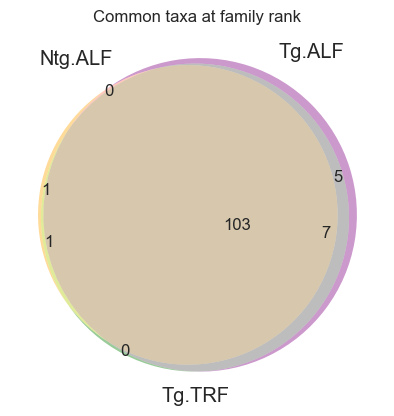

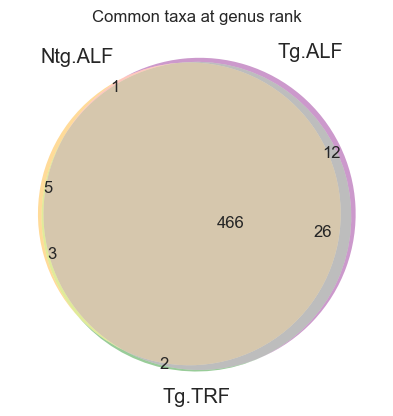

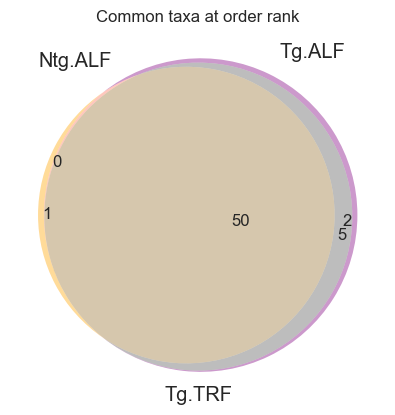

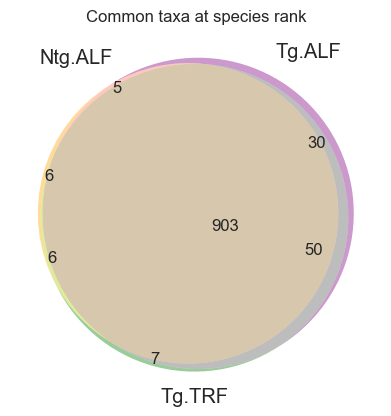

In [65]:
for rank in ranks:
    v = venn3(
        subsets=[presence_by_rank[rank][c] for c in genotype_diets], 
        set_labels=genotype_diets,
        set_colors=[genotype_diet_palette[c] for c in genotype_diets],
    )
    plt.title(f"Common taxa at {rank} rank")
    plt.savefig(f"metagenomics/diversity_results/metagenomic.taxonomy_venn.{rank.lower()}.svg")
    plt.show()   